# InternCircle Task 3 – Customer Churn / Sales Trend Analysis

## Objective

To perform end-to-end analysis on an e-commerce sales dataset using Python and Pandas.

This project focuses on sales trends, customer purchasing behavior, customer segmentation, revenue analysis, and customer churn identification.

The analysis includes data cleaning, feature engineering, date extraction, pivot tables, trend calculations, visualizations, and actionable business recommendations.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io
import os

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Loading the E-Commerce Dataset

The UCI Online Retail dataset is used for this project. It contains transaction-level information such as invoice number, product, quantity, invoice date, unit price, customer ID, and country.

In [10]:
# Download the dataset

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("/content/online_retail")

# Find the Excel file
files = os.listdir("/content/online_retail")

excel_file = None

for file in files:
    if file.lower().endswith(".xlsx"):
        excel_file = file
        break

file_path = "/content/online_retail/" + excel_file

# Load dataset
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (541909, 8)


## 2. Exploring the Dataset

The column names and first few records are displayed to understand the structure of the dataset.

In [11]:
print("Column Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Dataset Information

The dataset information is checked to understand the data types, number of records, and memory usage.

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## 4. Missing Value Analysis

Missing values are identified because customer-level analysis requires valid CustomerID information.

In [13]:
missing_values = df.isnull().sum()

print("Missing Values:")
display(missing_values.to_frame("Missing_Count"))

Missing Values:


,Missing_Count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


## 5. Data Cleaning

The dataset is cleaned before analysis.

Cancelled transactions, invalid quantities, invalid prices, and records without CustomerID are removed.

This improves the reliability of sales and customer-level analysis.

In [14]:
# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Create a copy
df_clean = df.copy()

# Remove cancelled transactions
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.upper().str.startswith("C")
]

# Remove invalid quantities
df_clean = df_clean[
    df_clean["Quantity"] > 0
]

# Remove invalid prices
df_clean = df_clean[
    df_clean["UnitPrice"] > 0
]

# Remove missing CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Remove invalid dates
df_clean = df_clean.dropna(subset=["InvoiceDate"])

print("Cleaned dataset shape:", df_clean.shape)
print("Data cleaning completed successfully!")

Cleaned dataset shape: (397884, 8)
Data cleaning completed successfully!


## 6. Feature Engineering and Date Extraction

New features are created from the transaction data.

Revenue is calculated using Quantity and UnitPrice. Year, month, day, weekday, and hour are extracted from InvoiceDate for further analysis.

In [15]:
# Calculate revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Extract date features
df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["Month_Name"] = df_clean["InvoiceDate"].dt.month_name()
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M")
df_clean["Day"] = df_clean["InvoiceDate"].dt.day
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

print("Feature engineering completed!")

Feature engineering completed!


## 7. Checking the Engineered Features

The newly created features are displayed to verify that the feature engineering process was successful.

In [16]:
display(
    df_clean[
        [
            "InvoiceDate",
            "Quantity",
            "UnitPrice",
            "Revenue",
            "Year",
            "Month",
            "YearMonth",
            "DayOfWeek",
            "Hour"
        ]
    ].head(10)
)

,InvoiceDate,Quantity,UnitPrice,Revenue,Year,Month,YearMonth,DayOfWeek,Hour
0,2010-12-01 08:26:00,6,2.55,15.30,2010,12,2010-12,Wednesday,8
1,2010-12-01 08:26:00,6,3.39,20.34,2010,12,2010-12,Wednesday,8
2,2010-12-01 08:26:00,8,2.75,22.00,2010,12,2010-12,Wednesday,8
3,2010-12-01 08:26:00,6,3.39,20.34,2010,12,2010-12,Wednesday,8
4,2010-12-01 08:26:00,6,3.39,20.34,2010,12,2010-12,Wednesday,8
5,2010-12-01 08:26:00,2,7.65,15.30,2010,12,2010-12,Wednesday,8
6,2010-12-01 08:26:00,6,4.25,25.50,2010,12,2010-12,Wednesday,8
7,2010-12-01 08:28:00,6,1.85,11.10,2010,12,2010-12,Wednesday,8
8,2010-12-01 08:28:00,6,1.85,11.10,2010,12,2010-12,Wednesday,8
9,2010-12-01 08:34:00,32,1.69,54.08,2010,12,2010-12,Wednesday,8


## 8. Monthly Sales Trend

Monthly revenue is calculated to identify changes in sales performance over time.

In [17]:
monthly_sales = (
    df_clean
    .groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

print("Monthly Sales Revenue:")
display(monthly_sales.to_frame("Revenue"))

Monthly Sales Revenue:


,Revenue
YearMonth,
2010-12,572713.890
2011-01,569445.040
2011-02,447137.350
2011-03,595500.760
2011-04,469200.361
2011-05,678594.560
2011-06,661213.690
2011-07,600091.011
2011-08,645343.900


## 9. Sales Trend Visualization

A line chart is created to visualize the monthly revenue trend.

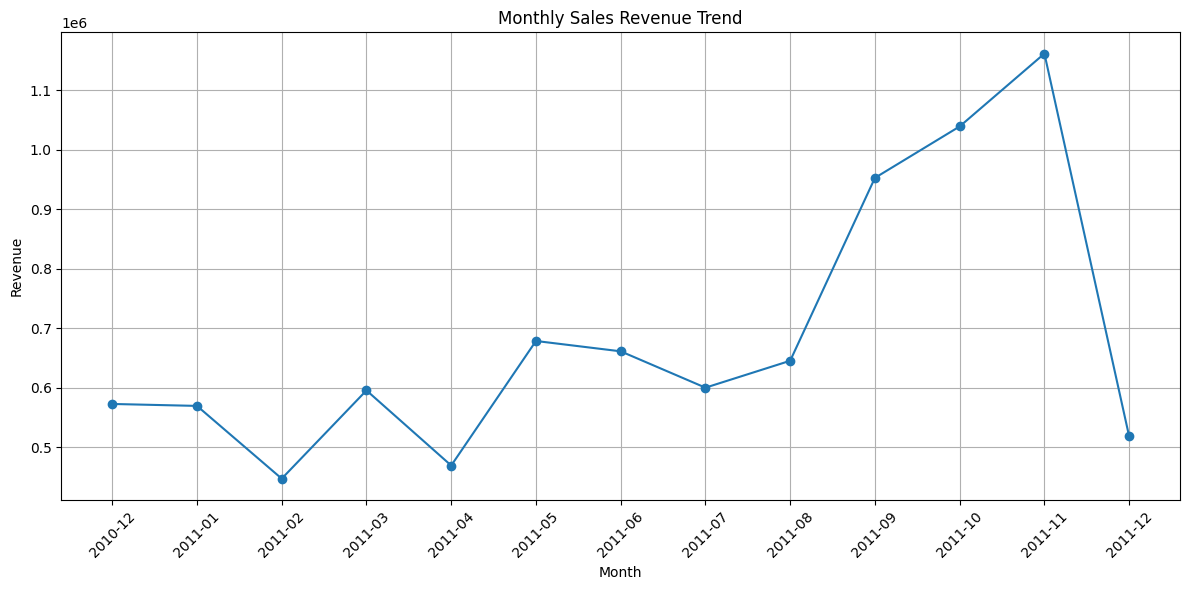

In [18]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

## 10. Monthly Revenue Growth

Month-over-month revenue growth is calculated to understand how sales change between consecutive months.

In [19]:
monthly_growth = monthly_sales.pct_change() * 100

growth_table = pd.DataFrame({
    "Revenue": monthly_sales,
    "Growth_Percentage": monthly_growth
})

display(growth_table.round(2))

,Revenue,Growth_Percentage
YearMonth,,
2010-12,572713.89,NaN
2011-01,569445.04,-0.57
2011-02,447137.35,-21.48
2011-03,595500.76,33.18
2011-04,469200.36,-21.21
2011-05,678594.56,44.63
2011-06,661213.69,-2.56
2011-07,600091.01,-9.24
2011-08,645343.90,7.54


## 11. Sales Pivot Table by Country

A pivot table is created to summarize total revenue generated by each country.

In [20]:
country_pivot = pd.pivot_table(
    df_clean,
    values="Revenue",
    index="Country",
    aggfunc="sum"
)

country_pivot = country_pivot.sort_values(
    by="Revenue",
    ascending=False
)

print("Top 10 Countries by Revenue:")
display(country_pivot.head(10))

Top 10 Countries by Revenue:


,Revenue
Country,
United Kingdom,7308391.554
Netherlands,285446.340
EIRE,265545.900
Germany,228867.140
France,209024.050
Australia,138521.310
Spain,61577.110
Switzerland,56443.950
Belgium,41196.340


## 12. Top Products by Revenue

Products are ranked according to their total revenue contribution.

In [21]:
top_products = (
    df_clean
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
display(top_products.to_frame("Revenue"))

Top 10 Products by Revenue:


,Revenue
Description,
"PAPER CRAFT , LITTLE BIRDIE",168469.60
REGENCY CAKESTAND 3 TIER,142592.95
WHITE HANGING HEART T-LIGHT HOLDER,100448.15
JUMBO BAG RED RETROSPOT,85220.78
MEDIUM CERAMIC TOP STORAGE JAR,81416.73
POSTAGE,77803.96
PARTY BUNTING,68844.33
ASSORTED COLOUR BIRD ORNAMENT,56580.34
Manual,53779.93


## 13. Customer Revenue Analysis

Customer-level revenue is calculated to identify customers who contribute significantly to total sales.

In [22]:
customer_revenue = (
    df_clean
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Revenue:")
display(
    customer_revenue.head(10).to_frame("Revenue")
)

Top 10 Customers by Revenue:


,Revenue
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194550.79
16446.0,168472.50
14911.0,143825.06
12415.0,124914.53
14156.0,117379.63
17511.0,91062.38
16029.0,81024.84


## 14. Customer Purchase Frequency

The number of unique invoices is calculated for each customer to understand purchase frequency.

In [23]:
customer_frequency = (
    df_clean
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Purchase Frequency:")
display(
    customer_frequency
    .head(10)
    .to_frame("Number_of_Orders")
)

Top 10 Customers by Purchase Frequency:


,Number_of_Orders
CustomerID,
12748.0,209
14911.0,201
17841.0,124
13089.0,97
14606.0,93
15311.0,91
12971.0,86
14646.0,73
16029.0,63


## 15. Customer Churn Analysis

Customer churn is estimated using customer recency.

The latest transaction date is used as the reference date. Customers whose last purchase was more than 90 days before the reference date are classified as churned.

The 90-day threshold is an analytical definition used for this project.

In [24]:
reference_date = df_clean["InvoiceDate"].max()

customer_data = (
    df_clean
    .groupby("CustomerID")
    .agg(
        LastPurchase=("InvoiceDate", "max"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalRevenue=("Revenue", "sum"),
        TotalQuantity=("Quantity", "sum")
    )
)

customer_data["Recency_Days"] = (
    reference_date - customer_data["LastPurchase"]
).dt.days

customer_data["Churn_Status"] = np.where(
    customer_data["Recency_Days"] > 90,
    "Churned",
    "Active"
)

print("Customer churn analysis completed!")
display(customer_data.head(10))

Customer churn analysis completed!


,LastPurchase,TotalOrders,TotalRevenue,TotalQuantity,Recency_Days,Churn_Status
CustomerID,,,,,,
12346.0,2011-01-18 10:01:00,1,77183.60,74215,325,Churned
12347.0,2011-12-07 15:52:00,7,4310.00,2458,1,Active
12348.0,2011-09-25 13:13:00,4,1797.24,2341,74,Active
12349.0,2011-11-21 09:51:00,1,1757.55,631,18,Active
12350.0,2011-02-02 16:01:00,1,334.40,197,309,Churned
12352.0,2011-11-03 14:37:00,8,2506.04,536,35,Active
12353.0,2011-05-19 17:47:00,1,89.00,20,203,Churned
12354.0,2011-04-21 13:11:00,1,1079.40,530,231,Churned
12355.0,2011-05-09 13:49:00,1,459.40,240,213,Churned


## 16. Churn Summary

The number and percentage of active and churned customers are calculated.

In [25]:
churn_count = (
    customer_data["Churn_Status"]
    .value_counts()
)

churn_percentage = (
    customer_data["Churn_Status"]
    .value_counts(normalize=True) * 100
)

print("Customer Churn Count:")
print(churn_count)

print("\nCustomer Churn Percentage:")
print(churn_percentage.round(2))

Customer Churn Count:
Churn_Status
Active     2893
Churned    1445
Name: count, dtype: int64

Customer Churn Percentage:
Churn_Status
Active     66.69
Churned    33.31
Name: proportion, dtype: float64


## 17. Customer Churn Visualization

A bar chart is created to compare the number of active and churned customers.

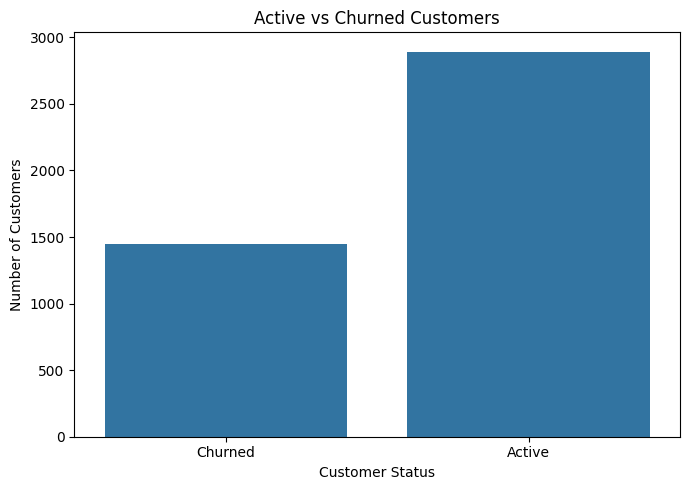

In [26]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=customer_data,
    x="Churn_Status"
)

plt.title("Active vs Churned Customers")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## 18. Customer Segmentation

Customers are segmented based on churn status, total revenue, and purchase frequency.

The segments are:
- Churned
- High Value
- Regular
- New / Occasional

In [27]:
revenue_75 = customer_data["TotalRevenue"].quantile(0.75)
orders_median = customer_data["TotalOrders"].median()

customer_data["Segment"] = np.select(
    [
        customer_data["Churn_Status"] == "Churned",
        customer_data["TotalRevenue"] >= revenue_75,
        customer_data["TotalOrders"] >= orders_median
    ],
    [
        "Churned",
        "High Value",
        "Regular"
    ],
    default="New / Occasional"
)

print("Customer Segment Counts:")
print(customer_data["Segment"].value_counts())

Customer Segment Counts:
Segment
Churned             1445
Regular             1272
High Value           990
New / Occasional     631
Name: count, dtype: int64


## 19. Revenue by Customer Segment

Total revenue generated by each customer segment is calculated.

In [28]:
segment_revenue = (
    customer_data
    .groupby("Segment")["TotalRevenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Customer Segment:")
display(
    segment_revenue.to_frame("Total_Revenue")
)

Revenue by Customer Segment:


,Total_Revenue
Segment,
High Value,6616560.720
Regular,1045909.522
Churned,1033364.081
New / Occasional,215573.581


## 20. Customer Segment Visualization

A horizontal bar chart is used to compare revenue across customer segments.

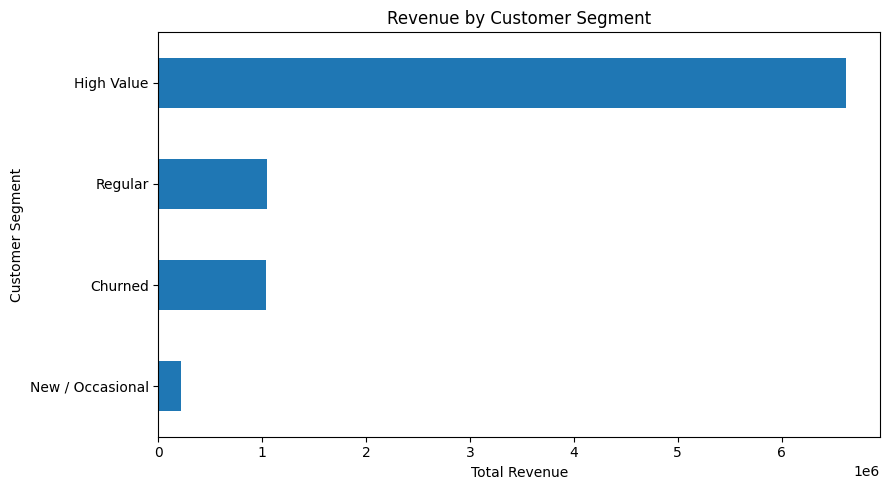

In [29]:
plt.figure(figsize=(9, 5))

segment_revenue.sort_values().plot(
    kind="barh"
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

## 21. Sales by Day of Week

Revenue is analyzed by day of the week to identify sales activity patterns.

In [30]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_sales = (
    df_clean
    .groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex(day_order)
)

print("Sales by Day of Week:")
display(day_sales.to_frame("Revenue"))

Sales by Day of Week:


,Revenue
DayOfWeek,
Monday,1367146.411
Tuesday,1700634.631
Wednesday,1588336.170
Thursday,1976859.070
Friday,1485917.401
Saturday,NaN
Sunday,792514.221


## 22. Sales by Hour

Revenue is analyzed by hour to identify periods of higher sales activity.

In [31]:
hourly_sales = (
    df_clean
    .groupby("Hour")["Revenue"]
    .sum()
    .sort_index()
)

print("Sales by Hour:")
display(hourly_sales.to_frame("Revenue"))

Sales by Hour:


,Revenue
Hour,
6,4.250
7,31059.210
8,282115.630
9,842605.171
10,1261192.571
11,1104558.750
12,1378571.480
13,1173264.750
14,995629.371


## 23. High-Value Churned Customers

Churned customers are sorted by their historical revenue to identify high-value customers who may require retention efforts.

In [32]:
churned_customers = (
    customer_data[
        customer_data["Churn_Status"] == "Churned"
    ]
    .sort_values(
        "TotalRevenue",
        ascending=False
    )
)

print("Top 10 High-Value Churned Customers:")

display(
    churned_customers[
        [
            "TotalOrders",
            "TotalRevenue",
            "Recency_Days"
        ]
    ].head(10)
)

Top 10 High-Value Churned Customers:


,TotalOrders,TotalRevenue,Recency_Days
CustomerID,,,
12346.0,1,77183.60,325
15749.0,3,44534.30,234
15098.0,3,39916.50,181
16180.0,8,10254.18,99
12590.0,2,9864.26,210
13093.0,8,7832.47,275
12980.0,9,7374.90,157
13027.0,6,6912.00,113
16553.0,12,5719.82,162


## 24. Key Findings

The analysis provides insights into sales trends, customer behavior, revenue contribution, customer churn, and customer segments.

The results can be used to understand important customer groups and sales patterns.

In [33]:
print("========== KEY FINDINGS ==========")

print("1. The e-commerce dataset was successfully cleaned.")
print("2. Revenue and date-based features were created.")
print("3. Monthly revenue trends were analyzed.")
print("4. Country-wise revenue was analyzed using a pivot table.")
print("5. Top revenue-generating products were identified.")
print("6. Customer revenue and purchase frequency were analyzed.")
print("7. Customer churn was estimated using recency.")
print("8. Customers were divided into different segments.")
print("9. High-value churned customers were identified.")
print("10. Sales patterns by day and hour were analyzed.")

========== KEY FINDINGS ==========
1. The e-commerce dataset was successfully cleaned.
2. Revenue and date-based features were created.
3. Monthly revenue trends were analyzed.
4. Country-wise revenue was analyzed using a pivot table.
5. Top revenue-generating products were identified.
6. Customer revenue and purchase frequency were analyzed.
7. Customer churn was estimated using recency.
8. Customers were divided into different segments.
9. High-value churned customers were identified.
10. Sales patterns by day and hour were analyzed.


## 25. Actionable Business Recommendations

The analysis can support business decisions related to customer retention, sales planning, product management, and targeted marketing.

In [34]:
print("========== CONCLUSION ==========")

print(
    "Customer Churn and Sales Trend Analysis was completed successfully."
)

print(
    "The project included data cleaning, feature engineering, "
    "sales trend analysis, pivot tables, customer analysis, "
    "churn identification, segmentation, visualization, "
    "and business recommendations."
)

print("Task 3 analysis completed successfully!")

========== CONCLUSION ==========
Customer Churn and Sales Trend Analysis was completed successfully.
The project included data cleaning, feature engineering, sales trend analysis, pivot tables, customer analysis, churn identification, segmentation, visualization, and business recommendations.
Task 3 analysis completed successfully!
